[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/SinaGhanbarii/gasmem/blob/main/notebooks/01_well_mixed.ipynb)

# 1 · Well-mixed (complete mixing) model

Both sides of the membrane are perfectly mixed, so the whole membrane sees the **outlet**
compositions: retentate $x$ and permeate $y$. It is the most pessimistic flow pattern and the only
one with a closed-form solution.

For a binary with selectivity $\alpha = Q_A/Q_B$ and pressure ratio $\varphi = p_h/p_l$:

$$\frac{y}{1-y} = \frac{\alpha\,(x - y/\varphi)}{(1-x) - (1-y)/\varphi}
\qquad\text{(rate equation)}$$

$$x_F = \theta\,y + (1-\theta)\,x \qquad\text{(mass balance)}$$

Substituting $x$ from the mass balance gives a quadratic $a y^2 + b y + c = 0$, so $y$, $x$ and the
area $A = \theta F / J_{tot}$ follow directly.

For **n components** the same two equations combine into
$y_i = \dfrac{Q_i p_h x_{F,i}/(1-\theta)}{J_{tot} + Q_i p_l + Q_i p_h\,\theta/(1-\theta)}$,
and $\sum y_i = 1$ is one equation in the single unknown $J_{tot}$.

In [1]:
\
# --- Find the toolkit (works on your own computer and in Google Colab) ---
import sys, os, glob, pathlib

def _find_toolkit():
    here = pathlib.Path.cwd()
    for p in [here, *here.parents]:                       # running from inside the folder
        if (p / "gasmem" / "__init__.py").exists():
            return p
    for pat in ["/content/*/gasmem/__init__.py",           # Colab: repository cloned into /content
                "/content/drive/MyDrive/gasmem/__init__.py",
                "/content/drive/MyDrive/*/gasmem/__init__.py",
                "/content/drive/MyDrive/*/*/gasmem/__init__.py",
                "/content/drive/MyDrive/*/*/*/gasmem/__init__.py"]:
        hits = sorted(glob.glob(pat))
        if hits:
            return pathlib.Path(hits[0]).parents[1]
    return None

TOOLKIT = _find_toolkit()
try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

REPO = "https://github.com/SinaGhanbarii/gasmem.git"
if TOOLKIT is None and IN_COLAB:
    # opened from the "Open in Colab" badge: fetch the toolkit from GitHub
    import subprocess
    print("Downloading the toolkit from", REPO)
    if subprocess.run(["git", "clone", "-q", "--depth", "1", REPO, "/content/gasmem"]).returncode:
        print("Download failed; looking in your Google Drive instead (approve the access request)")
        from google.colab import drive
        drive.mount("/content/drive")
    TOOLKIT = _find_toolkit()
if IN_COLAB:
    from google.colab import output
    output.enable_custom_widget_manager()               # makes the sliders work in Colab
if TOOLKIT is None:
    raise FileNotFoundError("Could not find the 'gasmem' folder. Open this notebook from inside "
                            "your copy of the repository (git clone " + REPO + ").")
sys.path.insert(0, str(TOOLKIT))
os.chdir(TOOLKIT / "notebooks")
print("Using toolkit at", TOOLKIT)
# ---------------------------------------------------------------------------

import numpy as np, pandas as pd, matplotlib.pyplot as plt
import ipywidgets as w
from IPython.display import display, Markdown
from gasmem import *
import gasmem.plotting as gasmem_plot
from gasmem.plotting import (plot_stage_cut_tradeoff, plot_purity_recovery, plot_profiles,
                             bar_breakdown, COLORS, MARKERS)
pd.set_option("display.precision", 4)

Using toolkit at /home/claude/gas-membrane-stagecut-toolkit


## The closed form, step by step

In [2]:
sol = well_mixed_binary(alpha=10, phi=4, x_feed=0.209, theta=0.2)
a, b, c = sol["coefficients"]
print(f"quadratic: {a:.4f} y^2 + {b:.4f} y + {c:.4f} = 0")
print(f"permeate y = {sol['y']:.4f}, retentate x = {sol['x']:.4f}, "
      f"dimensionless area = {sol['area_dimless']:.4f}")

quadratic: -4.5000 y^2 + 8.1013 y + -2.6125 = 0
permeate y = 0.4209, retentate x = 0.1560, dimensionless area = 1.6566


## How selectivity changes the trade-off (φ = 10, x_F = 0.2)

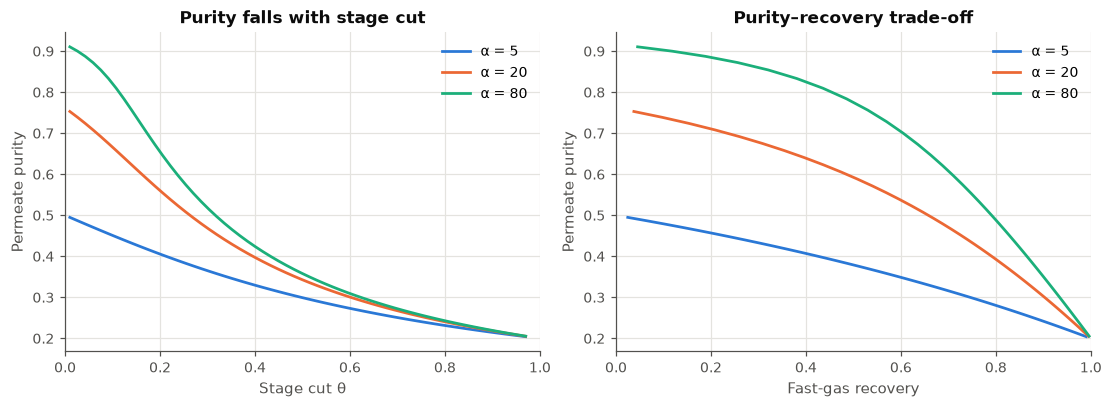

In [3]:
th = np.linspace(0.01, 0.97, 60)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.6), constrained_layout=True)
for k, alpha in enumerate([5, 20, 80]):
    d = pd.DataFrame([well_mixed_binary(alpha, 10, 0.2, t) for t in th]).assign(theta=th)
    col = ["#2a78d6", "#eb6834", "#1baf7a"][k]
    ax[0].plot(d["theta"], d["y"], color=col, label=f"α = {alpha}")
    ax[1].plot(d["theta"] * d["y"] / 0.2, d["y"], color=col, label=f"α = {alpha}")
ax[0].set(xlabel="Stage cut θ", ylabel="Permeate purity", title="Purity falls with stage cut", xlim=(0, 1))
ax[1].set(xlabel="Fast-gas recovery", ylabel="Permeate purity", title="Purity–recovery trade-off", xlim=(0, 1))
ax[0].legend(); ax[1].legend();

Going from α = 20 to α = 80 gains far less than going from 5 to 20: with φ = 10 the separation
becomes pressure-ratio limited.

## Interactive: move the stage cut and watch the trade-off

In [4]:
def explore(alpha=10.0, phi=4.0, x_feed=0.2, theta=0.3):
    th = np.linspace(0.01, 0.97, 60)
    rows = [dict(theta=t, **{k: v for k, v in well_mixed_binary(alpha, phi, x_feed, t).items()
                              if k != "coefficients"}) for t in th]
    d = pd.DataFrame(rows)
    d["recovery"] = d["theta"] * d["y"] / x_feed
    now = well_mixed_binary(alpha, phi, x_feed, theta)
    fig, ax = plt.subplots(1, 3, figsize=(11, 3.3), constrained_layout=True)
    for a_, col, ttl, yl in [(ax[0], "y", "Permeate purity (fast gas)", "Mole fraction"),
                              (ax[1], "recovery", "Fast-gas recovery", "Fraction of feed"),
                              (ax[2], "area_dimless", "Membrane area", "A·Q_A·p_h / F")]:
        a_.plot(d["theta"], d[col], color=COLORS["well_mixed"])
        a_.axvline(theta, color="#52514e", ls="--", lw=1)
        a_.set_title(ttl); a_.set_ylabel(yl); a_.set_xlabel("Stage cut θ"); a_.set_xlim(0, 1)
    ax[0].plot(d["theta"], d["x"], color=COLORS["well_mixed"], ls=":", label="retentate x")
    ax[0].legend()
    plt.show()
    display(Markdown(f"At θ = {theta:.2f}: permeate **{now['y']:.3f}**, retentate **{now['x']:.3f}**, "
                     f"recovery **{theta*now['y']/x_feed:.3f}**, area **{now['area_dimless']:.3f}**"))

w.interact(explore,
           alpha=w.FloatSlider(value=10, min=1.5, max=100, step=0.5, continuous_update=False, description="α"),
           phi=w.FloatSlider(value=4, min=1.2, max=100, step=0.2, continuous_update=False, description="φ"),
           x_feed=w.FloatSlider(value=0.2, min=0.02, max=0.9, step=0.01, continuous_update=False, description="x feed"),
           theta=w.FloatSlider(value=0.3, min=0.01, max=0.97, step=0.01, continuous_update=False, description="θ"));

interactive(children=(FloatSlider(value=10.0, continuous_update=False, description='α', min=1.5, step=0.5), Fl…

## Multicomponent example: oxygen enrichment from air

In [5]:
m = Membrane(MEMBRANE_PRESETS["Asymmetric hollow fibre air (Feng 1999)"])
print(m)
for th in (0.1, 0.3, 0.6):
    print(well_mixed(m, FEED_PRESETS["air, 20.5% O2 (Feng 1999)"], th, p_high=8.0, p_low=1.0, feed_flow=1.0).summary(), "\n")

Membrane('': O2=9.198, N2=1.703 GPU)
well_mixed: stage cut = 0.1000, area = 156.7 m2, p_h/p_l = 8/1 bar
  comp     feed  retent.    perm.  rec->perm
    O2   0.2050   0.1767   0.4599     0.2243
    N2   0.7950   0.8233   0.5401     0.0679 

well_mixed: stage cut = 0.3000, area = 523.7 m2, p_h/p_l = 8/1 bar
  comp     feed  retent.    perm.  rec->perm
    O2   0.2050   0.1332   0.3725     0.5451
    N2   0.7950   0.8668   0.6275     0.2368 

well_mixed: stage cut = 0.6000, area = 1162 m2, p_h/p_l = 8/1 bar
  comp     feed  retent.    perm.  rec->perm
    O2   0.2050   0.0935   0.2793     0.8175
    N2   0.7950   0.9065   0.7207     0.5439 



**Takeaway.** In a well-mixed stage the entire membrane works against the leanest (retentate)
composition, so permeate purity falls steeply with stage cut. The other flow patterns in
notebooks 02–03 do better because the feed-side composition varies along the module.